# The solver's modes and friction

The experiment: a cube on a slope, where friction must hold it or let it slide at the rate
Coulomb's law gives.

In [1]:
import os
os.environ.setdefault("MUJOCO_GL", "egl")  # headless rendering; use "glfw" on a desktop

import time
import numpy as np
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import warp as wp

wp.config.log_level = wp.LOG_WARNING  # no init banner
wp.init()
print("device:", wp.get_device())

device: cuda:0


## A cube on a slope

Tilting gravity by 20 degrees makes the floor a slope. With `mu = 0.5 > tan 20 = 0.36` the cube
should stay put; with `mu = 0.2` it should slide at `g (sin 20 - mu cos 20)`, on the slope.

exact                    mu 0.5:   0.007 mm in the last second | mu 0.2: 1.5115 m/s^2, highest after 0.5 s  -0.033 mm from rest | within capacities: True


exact, no de Saxce term  mu 0.5:   0.009 mm in the last second | mu 0.2: 1.5102 m/s^2, highest after 0.5 s +14.762 mm from rest | within capacities: True


mj                       mu 0.5:   0.977 mm in the last second | mu 0.2: 1.5154 m/s^2, highest after 0.5 s  +1.118 mm from rest | within capacities: True


exact, ray groups        mu 0.5:  53.085 mm in the last second | mu 0.2: 1.5123 m/s^2, highest after 0.5 s  -0.134 mm from rest | within capacities: True


exact, cone groups       mu 0.5:   0.013 mm in the last second | mu 0.2: 1.5115 m/s^2, highest after 0.5 s  -0.157 mm from rest | within capacities: True
Coulomb                  mu 0.5:   0.000 mm in the last second | mu 0.2: 1.5115 m/s^2, on the slope
a ray's friction carries tan 20 = 0.364 of its normal force at mu 0.5 only while slipping at 53.1 mm/s (stiction 0.05 m/s)


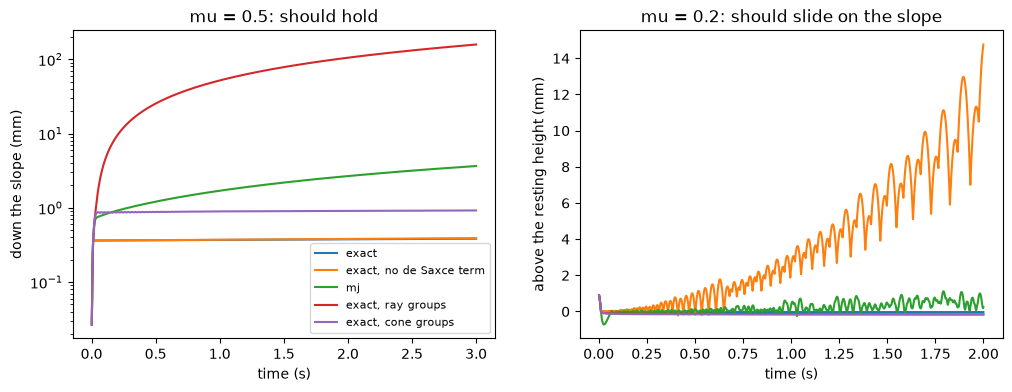

In [2]:
from lodos import sim as lsim, step
from lodos.col.sdf import PlaneSurface
from viewer.scenes.assets import load_surface

def slope(mu, **options):
    g, theta = 9.81, np.radians(20.0)
    mjm = mujoco.MjModel.from_xml_string(f"""<mujoco>
      <option timestep="0.002" gravity="{g * np.sin(theta)} 0 {-g * np.cos(theta)}" cone="elliptic"/>
      <worldbody><geom name="floor" type="plane" size="50 50 0.1" friction="{mu}"/>
        <body name="cube" pos="0 0 0.501"><freejoint/>
          <geom name="cube" type="box" size="0.5 0.5 0.5" density="100" contype="0" conaffinity="0" friction="{mu}"/></body>
      </worldbody></mujoco>""")
    gid = lambda n: mujoco.mj_name2id(mjm, mujoco.mjtObj.mjOBJ_GEOM, n)
    surfaces = lsim.Surfaces(surfaces=[load_surface("cube"), PlaneSurface()], geoms=[gid("cube"), gid("floor")],
                             pairs=[(0, 1)], mu=mu)
    return lsim.make_sim(mjm, 1, surfaces=surfaces, solver_kwargs=options, nconmax=64, njmax=256)

def run(sim, steps):
    # The cube's position before the first step and after each, and whether every count stayed within its capacity.
    replay = step.make_step_graph(sim)
    p, ok = [sim.drbd.qpos.numpy()[0, :3].copy()], True
    for _ in range(steps):
        replay()
        p.append(sim.drbd.qpos.numpy()[0, :3].copy())
        ok &= int(sim.d.nacon.numpy()[0]) <= sim.d.naconmax and int(sim.d.nefc.numpy().max()) < sim.d.njmax
    return np.array(p), ok and not sim.dcol.overflow.numpy().any()

theta = np.radians(20)
runs = {
    "exact": {},
    "exact, no de Saxce term": dict(de_saxce=False),
    "mj": dict(mode="mj"),
    "exact, ray groups": dict(groups="ray"),
    "exact, cone groups": dict(groups="cone"),
}
t_hold, t_slide = np.arange(1, 1501) * 0.002, np.arange(1, 1001) * 0.002
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for label, opts in runs.items():
    p, ok1 = run(slope(0.5, **opts), len(t_hold))       # held: 3 s
    x = (p[1:, 0] - p[0, 0]) * 1e3                       # down the slope, mm
    p, ok2 = run(slope(0.2, **opts), len(t_slide))      # sliding: 2 s
    z = (p[1:, 2] - 0.5) * 1e3                           # above the resting height, mm
    a = 2 * np.polyfit(t_slide[250:], p[251:, 0], 2)[0]  # the acceleration down the slope after 0.5 s
    ax[0].plot(t_hold, x, label=label)
    ax[1].plot(t_slide, z, label=label)
    print(f"{label:24s} mu 0.5: {x[-1] - x[-501]:7.3f} mm in the last second | mu 0.2: {a:6.4f} m/s^2, "
          f"highest after 0.5 s {z[250:].max():+7.3f} mm from rest | within capacities: {ok1 and ok2}")
print(f"{'Coulomb':24s} mu 0.5: {0:7.3f} mm in the last second | mu 0.2: "
      f"{9.81 * (np.sin(theta) - 0.2 * np.cos(theta)):6.4f} m/s^2, on the slope")
stiction = lsim.default_pair_params(0.5, 1)[0, 4]
tan = np.tan(theta)
print(f"a ray's friction carries tan 20 = {tan:.3f} of its normal force at mu 0.5 only while slipping at "
      f"{stiction * tan / np.sqrt(0.5 ** 2 - tan ** 2) * 1e3:.1f} mm/s (stiction {stiction:g} m/s)")
ax[0].set(title="mu = 0.5: should hold", xlabel="time (s)", ylabel="down the slope (mm)", yscale="log")
ax[1].set(title="mu = 0.2: should slide on the slope", xlabel="time (s)", ylabel="above the resting height (mm)")
ax[0].legend(fontsize=8); plt.show()

Held at `mu = 0.5`, the exact mode holds the cube: after landing it moves 0.007 mm in the last
second, 0.009 mm without the de Saxcé term, and 0.013 mm with its contacts in a cone group (one,
for the pair). MuJoCo's friction rows are soft, and hold a load only while slipping a little:
under the mj mode the cube creeps at about 1 mm/s. A ray group's friction depends on the slip,
and can carry `tan 20` of the normal force only at the 53.1 mm/s sliding velocity printed above.

Sliding at `mu = 0.2`, every configuration accelerates within 0.3% of Coulomb's 1.51 m/s^2, and
the de Saxcé term is what keeps the exact mode on the slope. Without it the problem is its
convex relaxation, in which a sliding contact lifts off at `mu` times its slip: the cube bounces
off the slope, higher as it slides faster, more than a centimetre by 2 s.
With the term the cube stays down. The mj mode, which takes no de Saxcé term by
default, bounces.